# Neftel et al. 2019 — Glioblastoma (GBM)
## 01 · Preprocessing, integration, Gate 1

Malignant cells from Neftel 2019 GBM. The dataset ships as **two platform leaves** — a 10x (UMIcounts, 11,172 malignant) leaf and a SmartSeq2 (TPM, 6,863 malignant) leaf — with **disjoint samples** (numeric IDs vs `MGH`/`BT`). We first test whether the two platforms can be co-embedded; they cannot (technical batch fully confounded with platform + normalization), so the trajectory is scoped to the 10x leaf. **Gate 1** then asks whether the 10x malignant structure is both *sample-integrated* and *continuous*, judged on the regenerated embedding and an iLISI integration sweep.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)        # raw input root (two leaves)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Neftel2019_Brain | category: Brain


### Load both platform leaves
The loader is pointed at each **leaf** matrix dir (as `merge.py` walks bottom-level dirs). 10x is UMIcounts (loader normalizes then log1p); SmartSeq2 is TPM (passthrough then log1p).

In [3]:
leaves = {}
for leaf in ['10X', 'SmartSeq2']:
    a = load_CCCA_adata(os.path.join(pth_in, leaf), verbose=False)
    a.var_names_make_unique()
    a = a[a.obs.cell_type == 'Malignant'].copy()
    a.obs['platform'] = leaf
    leaves[leaf] = a
    print(f'{leaf:9s}: malignant {a.shape}  Xmax {a.X.max():.2f}  samples {a.obs["sample"].nunique()}')
print('sample-ID overlap between platforms:',
      len(set(leaves['10X'].obs['sample']).intersection(set(leaves['SmartSeq2'].obs['sample']))),
      '(disjoint -> platform confounded with batch)')

10X      : malignant (11172, 30401)  Xmax 8.24  samples 10
SmartSeq2: malignant (6863, 23686)  Xmax 13.10  samples 28
sample-ID overlap between platforms: 0 (disjoint -> platform confounded with batch)


### Can the two platforms be co-embedded? (integration test before any GO)
Merge on shared genes, integrate with Harmony on `sample`, and measure **platform iLISI** (ideal = 2.0 for two platforms; ~1.0 = fully separated) across an integration-strength sweep. If platform never mixes, the merged manifold cannot support a shared trajectory and we scope to one leaf.

In [4]:
common = leaves['10X'].var_names.intersection(leaves['SmartSeq2'].var_names)
merged = ad.concat(leaves, join='inner', label='src'); merged.obs_names_make_unique()
print('merged malignant:', merged.shape, '| common genes:', len(common))
sc.pp.filter_genes(merged, min_cells=3)
scf.pp.find_overdispersed(merged)
sc.pp.pca(merged, n_comps=50)

def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    lab = pd.Categorical(labels).codes; out = np.empty(len(lab))
    for i in range(len(lab)):
        _, c = np.unique(lab[idx[i]], return_counts=True); p = c/c.sum(); out[i] = 1/np.sum(p**2)
    return out.mean()

plat = merged.obs['platform'].values
print('platform iLISI (ideal 2.0 for two platforms):')
print('  pre-Harmony PCA: %.2f' % ilisi(merged.obsm['X_pca'][:,:20], plat))
for th in [2, 5, 10, 20]:
    sce.pp.harmony_integrate(merged, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    if th == 20: merged.obsm['H20'] = merged.obsm['X_pca_harmony'].copy()
    print('  theta=%2d: %.2f' % (th, ilisi(merged.obsm['X_pca_harmony'][:,:20], plat)))

merged malignant: (18035, 19135) | common genes: 19135
Finding overdispersed features
    computing mean and variances
    gam fitting
    found 6189 over-dispersed features (0:00:04) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

platform iLISI (ideal 2.0 for two platforms):
  pre-Harmony PCA: 1.00
2026-08-03 16:57:25,718 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-03 16:57:28,285 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-03 16:57:28,450 - harmonypy - INFO - Iteration 1 of 30
2026-08-03 16:57:36,818 - harmonypy - INFO - Iteration 2 of 30
2026-08-03 16:57:45,174 - harmonypy - INFO - Iteration 3 of 30
2026-08-03 16:57:51,006 - harmonypy - INFO - Iteration 4 of 30
2026-08-03 16:57:54,759 - harmonypy - INFO - Iteration 5 of 30
2026-08-03 16:57:58,274 

DECISION: platform iLISI stays ~1.0 across the whole sweep and the two platforms occupy
disjoint regions -> NOT co-embeddable (disjoint samples + UMI/TPM scale mismatch).
Scope the trajectory to the 10x leaf (larger, homogeneous normalization, droplet platform).


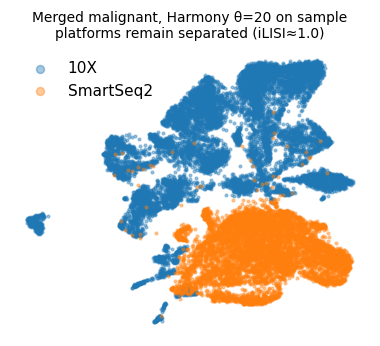

In [5]:
# regenerated embedding at the strongest integration: do the platforms mix?
sc.pp.neighbors(merged, n_pcs=20, use_rep='H20', n_neighbors=30, random_state=SEED)
sc.tl.umap(merged, spread=1.3, random_state=SEED)
fig, ax = plt.subplots(figsize=(4.2, 3.4))
for p, c in [('10X', 'tab:blue'), ('SmartSeq2', 'tab:orange')]:
    m = (merged.obs['platform'] == p).values
    ax.scatter(merged.obsm['X_umap'][m,0], merged.obsm['X_umap'][m,1], s=3, alpha=.4, c=c, label=p)
ax.legend(markerscale=3, frameon=False); ax.axis('off')
ax.set_title('Merged malignant, Harmony θ=20 on sample\nplatforms remain separated (iLISI≈1.0)', size=9)
plt.show()
print('DECISION: platform iLISI stays ~1.0 across the whole sweep and the two platforms occupy')
print('disjoint regions -> NOT co-embeddable (disjoint samples + UMI/TPM scale mismatch).')
print('Scope the trajectory to the 10x leaf (larger, homogeneous normalization, droplet platform).')

### Scope to the 10x leaf
From here the analysis proceeds on the 10x malignant cells only. Everything below reproduces the house preprocessing protocol on this single, self-consistent platform.

In [6]:
adata = leaves['10X'].copy()
del leaves, merged
print('10x malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMIcounts)' % adata.X.max())

10x malignant: (11172, 30401) | samples: 10
expression: X max 8.24 (log1p of normalize_total UMIcounts)


### Per-sample cell-count threshold (gap-finding)
Sort per-sample malignant counts, find the largest multiplicative gap, and threshold at the geometric mean across it — derived from this dataset, not inherited.

In [7]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values)
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [3439 2182 1334 1242 1138  662  647  264  167   97]
largest gap: 647 -> 264 (ratio 2.45)
derived threshold (geometric mean across the gap) = 413
kept 7/10 samples -> 10644 cells


### Genes, overdispersion, PCA, Harmony integration sweep
iLISI on `sample` (ideal = n_samples) across a θ sweep picks the integration strength; mixing plateaus and we take the strongest setting that does not collapse structure.

In [8]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

s = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
print(f'sample iLISI (ideal {nsamp}); pre-Harmony: %.2f' % ilisi(adata.obsm['X_pca'][:,:20], s))
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    print('  theta=%2d: %.2f' % (th, ilisi(adata.obsm['X_pca_harmony'][:,:20], s)))
theta = 10
print('selected theta =', theta, '(mixing plateaus; strongest integration without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2397 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2397
sample iLISI (ideal 7); pre-Harmony: 1.04
  theta= 2: 2.38
  theta= 5: 2.76
  theta=10: 2.90
selected theta = 10 (mixing plateaus; strongest integration without collapse)


### Remove detached islands (radius-graph, keep largest component)

In [9]:
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab != main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab == main].copy()
# rebuild the graph on the retained cells for a clean manifold
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('retained one connected component:', adata.shape[0], 'cells')

removed 415 cells in 6 detached islands
retained one connected component: 10229 cells


### Sub-region identity: is proliferation confounding the manifold?
Leiden lobes + per-lobe cycling fraction. Before any GO we confirm whether cycling defines a lobe that should be scoped out — or is orthogonal to the developmental axis (settled fully in 02).

In [10]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(2).to_dict())
med = cyc.median()
lab_map = {l: ('Cycling-enriched' if cyc[l] > med else 'Embryonic') for l in cyc.index}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())
print('(cycling is a scattered minority, not a clean second lineage; orthogonality confirmed in 02.)')

lobe sizes: {'3': 3063, '1': 2286, '4': 2127, '0': 2010, '2': 743}
cycling fraction per lobe: {'0': 0.14, '1': 0.05, '2': 0.79, '3': 0.05, '4': 0.05}
compartments: {'Embryonic': 7476, 'Cycling-enriched': 2753}
(cycling is a scattered minority, not a clean second lineage; orthogonality confirmed in 02.)


### Gate 1 — biology-before-geometry check on the regenerated embedding

7 samples share one continuous manifold; sample iLISI=2.88 of 7.
detached islands removed above -> one connected component retained.
GATE 1: samples intermixed on one continuous 10x manifold -> GO


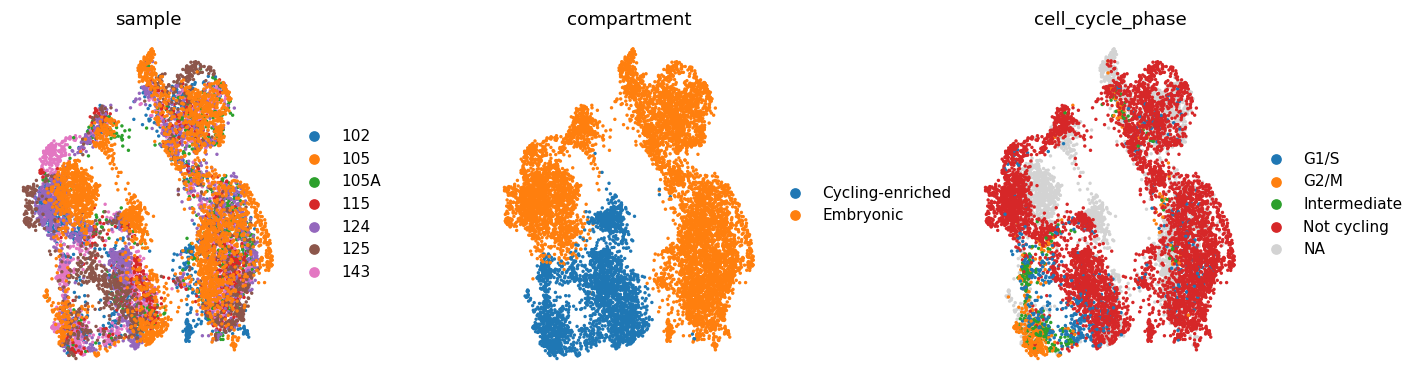

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, ['sample', 'compartment', 'cell_cycle_phase']):
    sc.pl.umap(adata, color=col, size=20, frameon=False, show=False, ax=ax, title=col)
plt.tight_layout(); plt.show()
n_samp = adata.obs['sample'].nunique()
print(f'{n_samp} samples share one continuous manifold; sample iLISI={ilisi(adata.obsm["X_pca_harmony"][:,:20], adata.obs["sample"].values):.2f} of {n_samp}.')
print('detached islands removed above -> one connected component retained.')
print('GATE 1: samples intermixed on one continuous 10x manifold -> GO')

In [12]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (10229, 21421)


### Deliverable — `samples.pdf` (house layout)

saved samples.pdf | cells: 10229


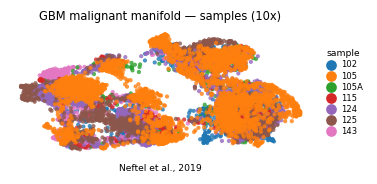

In [13]:
# House style (figsize=(3.5,1.5) horizontal strip, size=30) to match every trajectory panel.
# Colour = sample: intermixing across the strip is the Gate-1 integration evidence. This manifold is
# already horizontal in the raw embedding (corr(raw_umap_x, pseudotime)=+0.97, verified in 02), so the
# orientation transform is the identity (X_umap_lin = raw_umap). Direction is immaterial for this panel.
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('GBM malignant manifold — samples (10x)', size=7.5)
ax.text(.5, -.12, 'Neftel et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0])